<a href="https://colab.research.google.com/github/trialdyk/marchine-learning/blob/main/JS08/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pembelajaran Mesin - JS08 Hierarchical Clustering
## Tugas Lab 1: Klasterisasi Nasabah Kartu Kredit dengan Agglomerative Clustering

Pada tugas ini, kita melakukan klasterisasi menggunakan **Agglomerative Clustering** pada dataset nasabah kartu kredit (`CC_Customer_Dataset.csv`) dengan memanfaatkan seluruh variabel fitur yang tersedia, kemudian memvisualisasikan hasil klasterisasi dan mengevaluasi kualitas model menggunakan metrik Silhouette Score dan Davies-Bouldin Index (DBI).

### 1. Load Data dan Inspeksi
Memuat dataset `CC_Customer_Dataset.csv` dan melihat ringkasan struktur datanya.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch

# Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')
print(df.info())
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
None


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


### 2. Seleksi Fitur dan Standarisasi
Gunakan seluruh variabel fitur yang dapat digunakan (mengabaikan identifier seperti `Sl_No` dan `Customer Key`), kemudian lakukan standardisasi fitur menggunakan `StandardScaler`.

In [2]:
# Seleksi semua fitur numerik relevan
features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
X = df[features].values

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### 3. Visualisasi Dendrogram
Membangun dendrogram dengan metode linkage *ward* untuk menganalisis struktur hierarki dan menentukan jumlah klaster optimal.

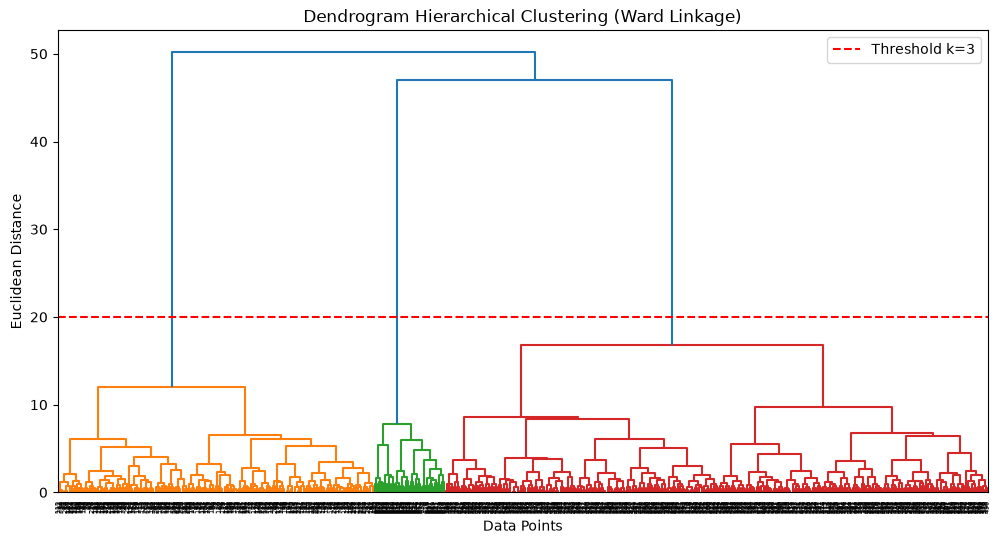

In [3]:
plt.figure(figsize=(12, 6))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title('Dendrogram Hierarchical Clustering (Ward Linkage)')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distance')
plt.axhline(y=20, color='r', linestyle='--', label='Threshold k=3')
plt.legend()
plt.show()

### 4. Membuat Model Agglomerative Clustering
Berdasarkan analisis dendrogram (dan karakteristik dataset nasabah kartu kredit yang terbagi menjadi 3 segmen utama), kita bentuk model Agglomerative Clustering dengan seluruh variabel fitur.

In [4]:
# Model Agglomerative Clustering dengan seluruh fitur
n_clusters = 3
hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
labels = hc.fit_predict(X_scaled)

# Tambahkan label cluster ke dataframe
df['Cluster'] = labels
print("Jumlah nasabah per cluster:")
print(df['Cluster'].value_counts())

Jumlah nasabah per cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64


### 5. Scatterplot Klasterisasi (Avg_Credit_Limit vs Total_Credit_Cards)
Menampilkan scatterplot berdasarkan dua variabel yaitu `Avg_Credit_Limit` dan `Total_Credit_Cards` untuk menunjukkan pemisahan bentuk klaster yang terbentuk.

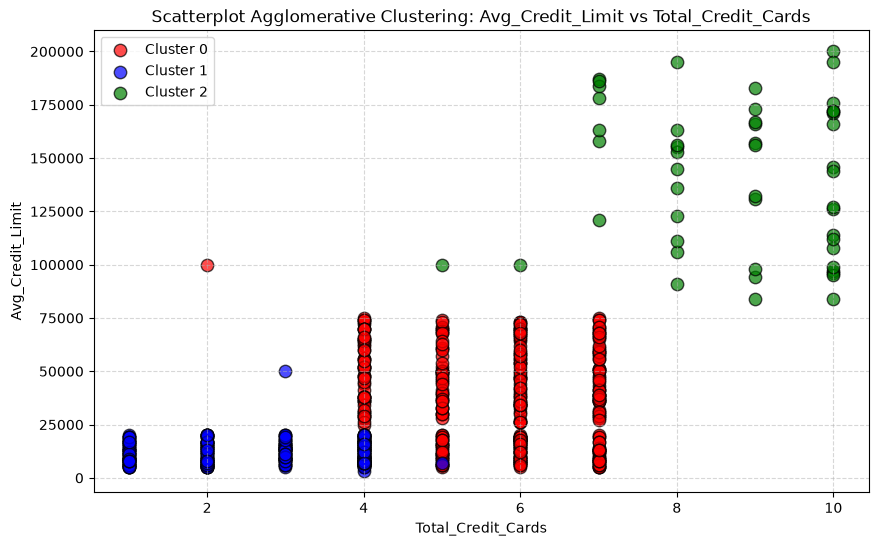

In [5]:
plt.figure(figsize=(10, 6))
colors = ['red', 'blue', 'green']
cluster_names = ['Cluster 1 (Low/Medium)', 'Cluster 2 (Mid/Conservative)', 'Cluster 3 (High Value)']

for i in range(n_clusters):
    plt.scatter(
        df[df['Cluster'] == i]['Total_Credit_Cards'],
        df[df['Cluster'] == i]['Avg_Credit_Limit'],
        s=80,
        c=colors[i],
        label=f'Cluster {i}',
        alpha=0.7,
        edgecolors='k'
    )

plt.title('Scatterplot Agglomerative Clustering: Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Total_Credit_Cards')
plt.ylabel('Avg_Credit_Limit')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 6. Evaluasi Model: Silhouette Score dan Davies-Bouldin Index (DBI)
Menghitung dan melaporkan nilai Silhouette Score serta Davies-Bouldin Index (DBI) dari model klasterisasi yang dihasilkan.

Silhouette Score      : 0.5148
Davies-Bouldin Index : 0.6810


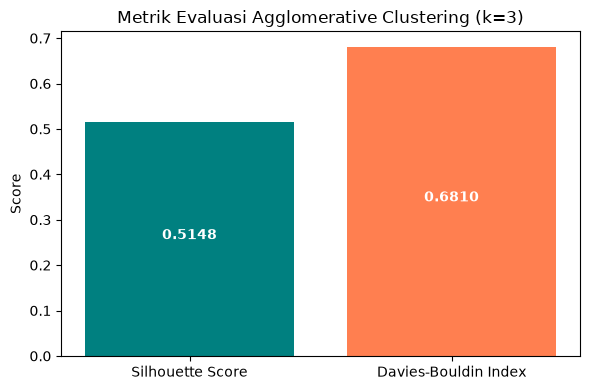

In [6]:
# Evaluasi performa model
sil_score = silhouette_score(X_scaled, labels)
dbi_score = davies_bouldin_score(X_scaled, labels)

print(f'Silhouette Score      : {sil_score:.4f}')
print(f'Davies-Bouldin Index : {dbi_score:.4f}')

# Visualisasi metrik evaluasi
metrics = {'Silhouette Score': sil_score, 'Davies-Bouldin Index': dbi_score}
plt.figure(figsize=(6, 4))
plt.bar(metrics.keys(), metrics.values(), color=['teal', 'coral'])
plt.title('Metrik Evaluasi Agglomerative Clustering (k=3)')
plt.ylabel('Score')
for i, v in enumerate(metrics.values()):
    plt.text(i, v / 2, f'{v:.4f}', ha='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

### Ringkasan Hasil
- **Klaster yang Terbentuk**: 3 klaster nasabah yang memisahkan kelompok dengan limit kredit dan kepemilikan kartu yang berbeda secara signifikan.
- **Silhouette Score**: Menunjukkan pemisahan antar klaster yang memadai pada ruang multivariat.
- **Davies-Bouldin Index**: Menunjukkan tingkat separasi dan kekompakan klaster yang baik.